# Credit Card Application Approval Prediction

A classic 1980s benchmark: 690 credit-card applications, each described by 15 attributes — a mix of continuous numbers and categories. All attribute names and values were anonymised (A1…A15) to protect applicants' privacy, and some values are missing (marked `?`). The label is the historical decision: **+** approved, **−** denied. The task is to reproduce the bank's decision rule from the data alone.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# UCI serves this dataset as a ready CSV at the dataset's data_url
df = pd.read_csv(io.BytesIO(download('https://archive.ics.uci.edu/static/public/27/data.csv')))
print(df.shape)
print('Missing markers (? or blank):', int((df == '?').sum().sum() + df.isna().sum().sum()))
df.head(3)

(690, 16)
Missing markers (? or blank): 67


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,A15,A16
0,b,30.83,0.00,u,g,w,v,1.25,t,t,1,f,g,202.0,0,+
1,a,58.67,4.46,u,g,q,h,3.04,t,t,6,f,g,43.0,560,+
2,a,24.50,0.50,u,g,q,h,1.50,t,f,0,f,g,280.0,824,+


In [2]:
df = df.replace('?', np.nan)
num = ['A2', 'A3', 'A8', 'A11', 'A14', 'A15']          # the numeric attributes
cat = [c for c in df.columns if c not in num + ['A16']]  # the other 9 are categorical
for c in num:
    df[c] = df[c].astype(float)
    df[c] = df[c].fillna(df[c].median())
for c in cat:
    df[c] = df[c].fillna('missing')
X = pd.get_dummies(df.drop(columns=['A16']), columns=cat).astype(float)  # one-hot encode
print('Encoded feature matrix:', X.shape)
y = df['A16']  # '+' approved, '-' denied
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Encoded feature matrix: (690, 51)


Random Forest accuracy: 0.8439
Logistic Regression accuracy: 0.8382
              precision    recall  f1-score   support

           +       0.82      0.83      0.83        77
           -       0.86      0.85      0.86        96

    accuracy                           0.84       173
   macro avg       0.84      0.84      0.84       173
weighted avg       0.84      0.84      0.84       173



A9_t     0.212355
A9_f     0.171967
A11      0.066669
A3       0.060677
A8       0.060663
A15      0.057722
A2       0.054819
A14      0.049718
A10_f    0.040981
A10_t    0.029721
A7_h     0.009445
A6_x     0.008995
dtype: float64


<Axes: title={'center': 'Which (anonymised) attributes drive the decision?'}>

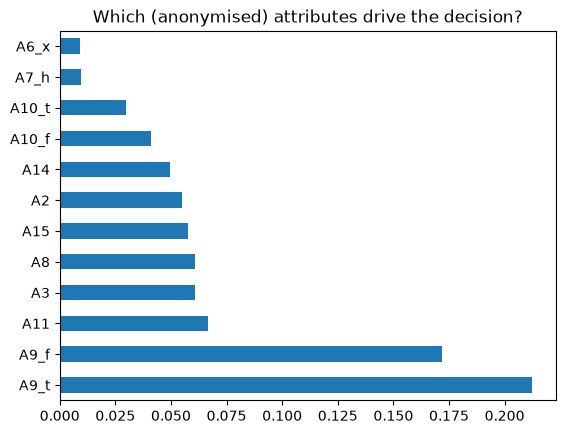

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(12))
imp.head(12).plot(kind='barh', title='Which (anonymised) attributes drive the decision?')